# 04 · Advanced Analysis
**Goal:** compare campaigns, find high- and under-performing segments, test cost efficiency, check correlations and unusual patterns, and turn the evidence into recommendations.

No machine learning is used: the data is aggregated daily by segment, and the questions here are answered better with transparent comparisons.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATA_PATH = Path("..") / "data" / "processed" / "advertising_cleaned.csv"
df = pd.read_csv(DATA_PATH)
df["month"] = pd.Categorical(df["month"], ["April", "May", "June"], ordered=True)
df["user_engagement"] = pd.Categorical(df["user_engagement"], ["Low", "Medium", "High"], ordered=True)

VALUE_COLS = ["displays", "cost", "clicks", "revenue", "post_click_conversions", "post_click_sales_amount"]

def summarize(data, by):
    """Totals per group plus ratios calculated from the totals (not averages of row ratios)."""
    out = data.groupby(by, observed=True)[VALUE_COLS].sum()
    out["CTR_%"] = out["clicks"] / out["displays"] * 100
    out["CPC"] = out["cost"] / out["clicks"]
    out["CPM"] = out["cost"] / out["displays"] * 1000
    out["conv_per_click_%"] = out["post_click_conversions"] / out["clicks"] * 100
    out["CPA"] = out["cost"] / out["post_click_conversions"]
    out["net_revenue"] = out["revenue"] - out["cost"]
    out["ROI_%"] = out["net_revenue"] / out["cost"] * 100
    out["cost_share_%"] = out["cost"] / data["cost"].sum() * 100
    return out

## 1. Campaign scorecard

In [2]:
campaign = summarize(df, "campaign_number")
campaign["avg_order_value"] = campaign["post_click_sales_amount"] / campaign["post_click_conversions"]
scorecard = campaign[["cost", "revenue", "net_revenue", "ROI_%", "CTR_%", "CPC", "CPM", "CPA", "conv_per_click_%", "avg_order_value"]]
scorecard.round(3)

,cost,revenue,net_revenue,ROI_%,CTR_%,CPC,CPM,CPA,conv_per_click_%,avg_order_value
campaign_number,,,,,,,,,,
camp 1,150688.122,230533.522,79845.399,52.987,0.983,0.107,1.051,0.238,44.927,48.987
camp 2,17037.350,34890.415,17853.066,104.788,1.937,0.019,0.375,1.238,1.562,84.805
camp 3,7466.748,10838.679,3371.931,45.159,0.403,0.037,0.149,1.520,2.426,108.947


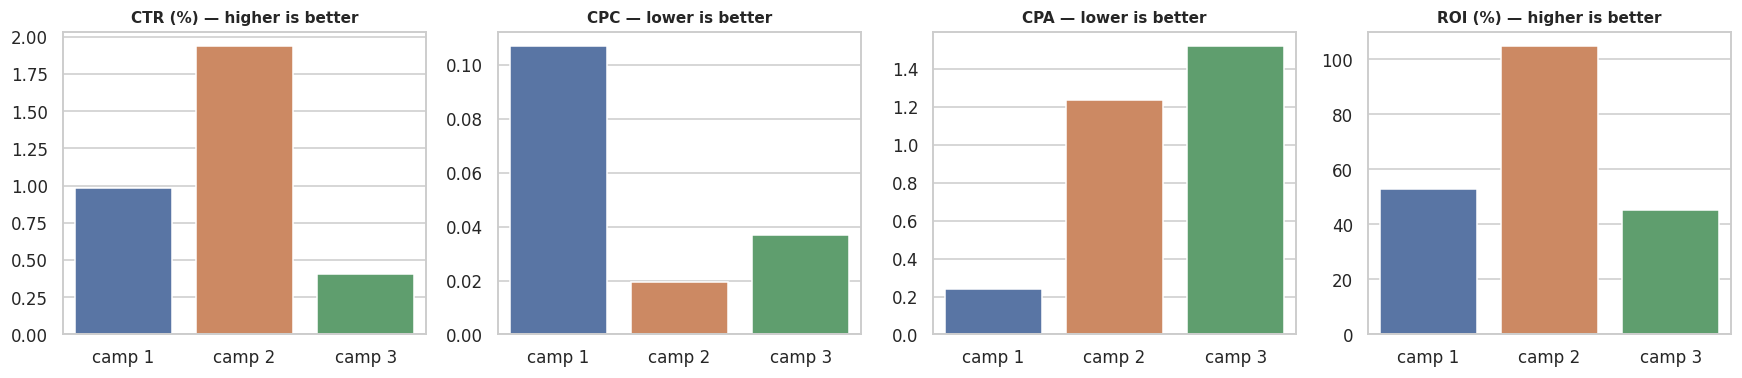

In [3]:
metrics = {"CTR_%": "CTR (%) — higher is better", "CPC": "CPC — lower is better",
           "CPA": "CPA — lower is better", "ROI_%": "ROI (%) — higher is better"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (col, title) in zip(axes, metrics.items()):
    sns.barplot(x=campaign.index, y=campaign[col], hue=campaign.index, palette="deep", legend=False, ax=ax)
    ax.set_title(title, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Reading the scorecard**
- Camp 2 wins on CTR, CPC and ROI, but it only ran in April (a like-for-like April comparison is below).
- Camp 1 spends the most, pays the highest CPC and has a middling ROI.
- `avg_order_value` differs a lot between campaigns ($49 vs $85 vs $109). Camp 1 reports many small conversions, which is why its conversions-per-click looks so high. Be careful reading conversion metrics across campaigns.

### Like-for-like comparison: April only (all three campaigns ran)

In [4]:
april = summarize(df[df["month"] == "April"], "campaign_number")
april[["cost", "revenue", "CTR_%", "CPC", "CPA", "ROI_%", "cost_share_%"]].round(3)

,cost,revenue,CTR_%,CPC,CPA,ROI_%,cost_share_%
campaign_number,,,,,,,
camp 1,68815.361,129230.445,1.135,0.098,0.291,87.793,77.481
camp 2,17037.350,34890.415,1.937,0.019,1.238,104.788,19.183
camp 3,2963.015,4222.100,0.369,0.037,1.982,42.493,3.336


## 2. Segment analysis: which combinations win or lose money?

In [5]:
SEGMENT = ["campaign_number", "user_engagement", "banner", "placement"]
MIN_COST = 500   # only judge segments with at least this much total cost (about 94% of all spend)

segments = summarize(df, SEGMENT).reset_index()
judged = segments[segments["cost"] >= MIN_COST].copy()
print(f"{len(segments)} segments in total; {len(judged)} have cost >= {MIN_COST} "
      f"and cover {judged['cost'].sum() / segments['cost'].sum():.1%} of spend.")

portfolio_roi = (df["revenue"].sum() - df["cost"].sum()) / df["cost"].sum() * 100
print(f"Portfolio ROI: {portfolio_roi:.1f}%")

def classify(roi):
    if roi < 0:
        return "Underperforming (ROI < 0)"
    if roi >= portfolio_roi:
        return "High performing (ROI >= portfolio)"
    return "Average (0 <= ROI < portfolio)"

judged["performance"] = judged["ROI_%"].apply(classify)
class_summary = judged.groupby("performance").agg(segments=("cost", "size"), cost=("cost", "sum"),
                                                   revenue=("revenue", "sum"), net_revenue=("net_revenue", "sum"))
class_summary["cost_share_%"] = class_summary["cost"] / judged["cost"].sum() * 100
class_summary.round(1)

244 segments in total; 38 have cost >= 500 and cover 94.2% of spend.
Portfolio ROI: 57.7%


,segments,cost,revenue,net_revenue,cost_share_%
performance,,,,,
Average (0 <= ROI < portfolio),7,37456.7,47687.8,10231.1,22.7
High performing (ROI >= portfolio),19,47043.8,143913.1,96869.4,28.5
Underperforming (ROI < 0),12,80599.5,66432.8,-14166.7,48.8


In [6]:
columns = SEGMENT + ["cost", "revenue", "net_revenue", "ROI_%", "CTR_%", "CPC"]
print("TOP 8 by net revenue (revenue - cost):")
display(judged.sort_values("net_revenue", ascending=False)[columns].head(8).round(2))
print("BOTTOM 8 by net revenue:")
display(judged.sort_values("net_revenue")[columns].head(8).round(2))

TOP 8 by net revenue (revenue - cost):


,campaign_number,user_engagement,banner,placement,cost,revenue,net_revenue,ROI_%,CTR_%,CPC
66,camp 1,High,240 x 400,ghi,23588.46,84455.83,60867.36,258.04,2.11,0.05
87,camp 1,High,728 x 90,ghi,20314.08,28101.78,7787.70,38.34,1.16,0.12
72,camp 1,High,300 x 250,ghi,3283.59,9489.05,6205.46,188.98,1.34,0.06
128,camp 2,Medium,240 x 400,ghi,4744.93,10814.24,6069.31,127.91,5.04,0.02
36,camp 1,Medium,240 x 400,ghi,1235.23,6722.53,5487.30,444.23,3.12,0.03
67,camp 1,High,240 x 400,jkl,1615.26,4304.51,2689.24,166.49,0.83,0.06
151,camp 2,Medium,728 x 90,mno,1512.15,3725.74,2213.59,146.39,1.28,0.02
126,camp 2,Medium,160 x 600,mno,1144.72,3338.37,2193.65,191.63,1.89,0.01


BOTTOM 8 by net revenue:


,campaign_number,user_engagement,banner,placement,cost,revenue,net_revenue,ROI_%,CTR_%,CPC
68,camp 1,High,240 x 400,mno,16943.47,12315.84,-4627.62,-27.31,0.70,0.24
74,camp 1,High,300 x 250,mno,23310.69,19075.04,-4235.65,-18.17,0.58,0.20
89,camp 1,High,728 x 90,mno,18817.65,16300.41,-2517.24,-13.38,0.45,0.19
86,camp 1,High,728 x 90,def,4542.09,3788.66,-753.43,-16.59,0.44,0.20
71,camp 1,High,300 x 250,def,2494.68,2006.91,-487.77,-19.55,0.44,0.20
83,camp 1,High,670 x 90,mno,1632.96,1281.15,-351.80,-21.54,0.60,0.20
63,camp 1,High,160 x 600,ghi,1561.97,1232.53,-329.43,-21.09,0.81,0.21
227,camp 3,High,300 x 250,mno,721.55,416.96,-304.60,-42.21,0.32,0.09


In [7]:
# Where the loss comes from
losers = judged[judged["ROI_%"] < 0]
print(f"{len(losers)} loss-making segments: cost ${losers['cost'].sum():,.0f}, "
      f"net loss ${-losers['net_revenue'].sum():,.0f}")
print("Loss-making segments by campaign / engagement:")
losers.groupby(["campaign_number", "user_engagement"], observed=True)[["cost", "net_revenue"]].sum().round(0)

12 loss-making segments: cost $80,599, net loss $14,167
Loss-making segments by campaign / engagement:


,,cost,net_revenue
campaign_number,user_engagement,,
camp 1,High,77359.0,-13597.0
camp 2,Medium,1977.0,-26.0
camp 3,High,1264.0,-544.0


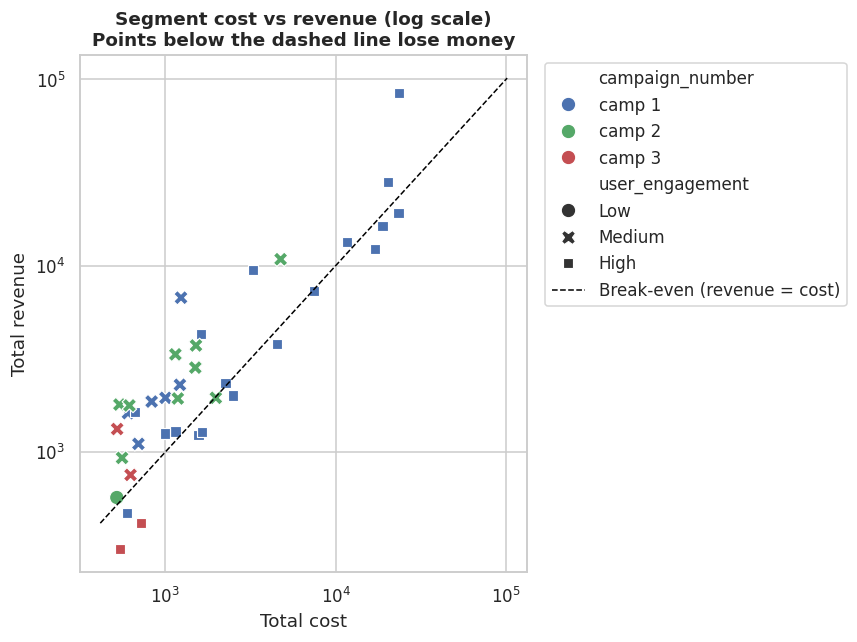

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
palette = {"camp 1": "#4C72B0", "camp 2": "#55A868", "camp 3": "#C44E52"}
sns.scatterplot(data=judged, x="cost", y="revenue", hue="campaign_number", style="user_engagement",
                palette=palette, s=90, ax=ax)
limit = [judged["cost"].min() * 0.8, judged["revenue"].max() * 1.2]
ax.plot(limit, limit, color="black", linestyle="--", linewidth=1, label="Break-even (revenue = cost)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Segment cost vs revenue (log scale)\nPoints below the dashed line lose money")
ax.set_xlabel("Total cost"); ax.set_ylabel("Total revenue")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 3. Cost efficiency: engagement level and placement inside Camp 1

In [9]:
camp1 = df[df["campaign_number"] == "camp 1"]
camp1_high = camp1[camp1["user_engagement"] == "High"]
by_place = summarize(camp1_high, "placement")
by_place[["cost", "revenue", "net_revenue", "ROI_%", "CTR_%", "CPC", "cost_share_%"]].round(2)

,cost,revenue,net_revenue,ROI_%,CTR_%,CPC,cost_share_%
placement,,,,,,,
Unknown,1.51,0.00,-1.51,-100.00,0.00,inf,0.00
abc,90.12,106.00,15.88,17.63,0.67,0.08,0.06
def,11062.55,9897.95,-1164.61,-10.53,0.48,0.18,7.72
ghi,49770.06,124537.35,74767.29,150.23,1.66,0.07,34.72
jkl,2543.74,6228.28,3684.54,144.85,0.73,0.07,1.77
mno,79876.93,69680.45,-10196.48,-12.77,0.62,0.19,55.72


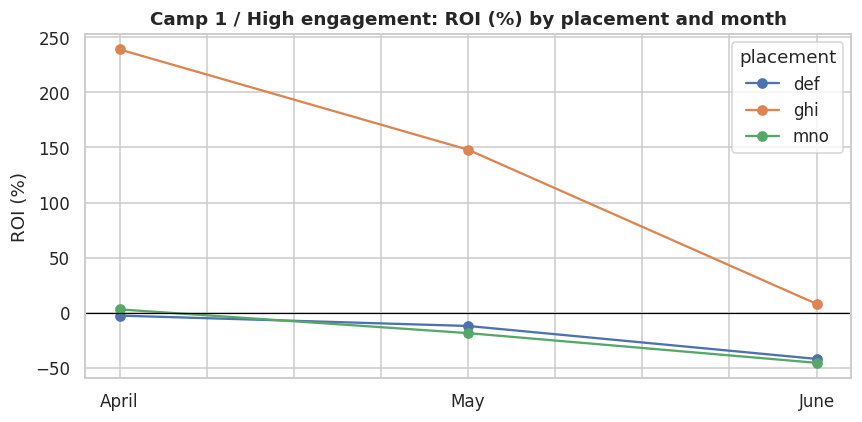

placement,def,ghi,mno
month,,,
April,-2.7,239.1,2.9
May,-12.2,147.9,-18.7
June,-42.1,7.9,-45.6


In [10]:
trend = summarize(camp1_high, ["month", "placement"]).reset_index()
trend = trend[trend["placement"].isin(["ghi", "mno", "def"])]
pivot = trend.pivot(index="month", columns="placement", values="ROI_%")
ax = pivot.plot(marker="o", figsize=(8, 4))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Camp 1 / High engagement: ROI (%) by placement and month")
ax.set_ylabel("ROI (%)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
pivot.round(1)

`ghi` is the profitable placement for Camp 1's high-engagement traffic in every month, while `mno` and `def` hover around break-even in April and lose money in May and June.

## 4. Correlations

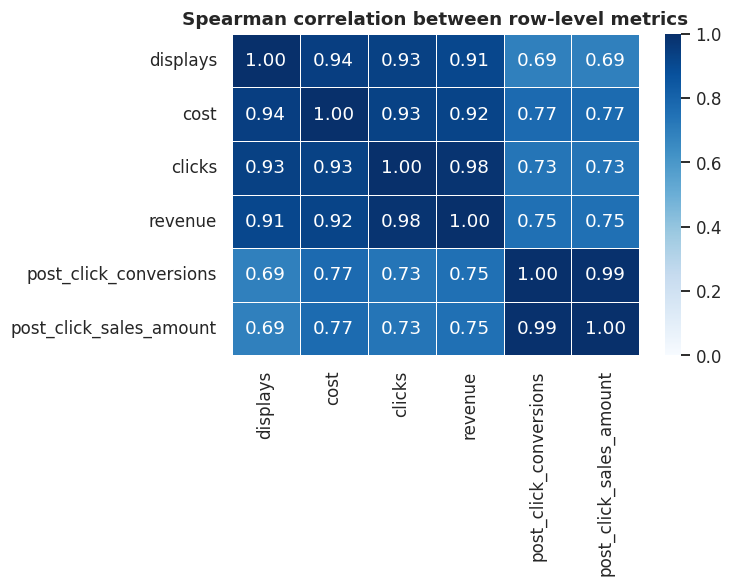

In [11]:
corr = df[VALUE_COLS].corr(method="spearman")   # rank-based, suitable for skewed data
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=0.5)
plt.title("Spearman correlation between row-level metrics")
plt.tight_layout(); plt.show()

- Displays, cost, clicks and revenue move together very strongly (0.91–0.98): bigger rows simply have bigger everything. These high values do **not** show efficiency.
- `post_click_sales_amount` and `post_click_conversions` are almost identical (0.99): sales amount is largely driven by the number of conversions.
- Correlation is not causation: it shows what rises together, not which spend decision caused a result.

In [12]:
# Efficiency check: does spending more per row bring a better return per dollar?
rows = df[(df["cost"] >= 1)].copy()
rows["row_ROI"] = (rows["revenue"] - rows["cost"]) / rows["cost"]
rows["cost_band"] = pd.qcut(rows["cost"], 5, labels=["Q1 (smallest)", "Q2", "Q3", "Q4", "Q5 (largest)"])
band = rows.groupby("cost_band", observed=True).agg(rows=("cost", "size"), cost=("cost", "sum"), revenue=("revenue", "sum"))
band["ROI_%"] = (band["revenue"] - band["cost"]) / band["cost"] * 100
band.round(1)

,rows,cost,revenue,ROI_%
cost_band,,,,
Q1 (smallest),1106,1489.0,3147.6,111.4
Q2,1105,2847.5,4892.6,71.8
Q3,1106,6045.4,8864.2,46.6
Q4,1105,15704.3,30654.0,95.2
Q5 (largest),1106,147224.8,225028.0,52.8


No steady pattern appears between row size and return: ROI by cost quintile is roughly +111%, +72%, +47%, +95%, +53%. This data gives no clear evidence that spending more per row either helps or hurts efficiency.

## 5. Unusual patterns

In [13]:
# (a) Daily ROI: which days lost money?
daily = df.groupby(["month_number", "day"], as_index=False)[["cost", "revenue"]].sum()
daily["ROI_%"] = (daily["revenue"] - daily["cost"]) / daily["cost"] * 100
loss_days = daily[daily["ROI_%"] < 0]
print(f"{len(loss_days)} of {len(daily)} days had negative ROI. By month:")
print(loss_days.groupby("month_number").size().rename({4: "April", 5: "May", 6: "June"}).to_string())
print()
print("Worst 5 days:")
daily.sort_values("ROI_%").head(5).round(1)

24 of 91 days had negative ROI. By month:
month_number
June    24

Worst 5 days:


,month_number,day,cost,revenue,ROI_%
89,6,29,1031.9,772.5,-25.1
85,6,25,690.7,519.8,-24.7
71,6,11,883.5,700.7,-20.7
65,6,5,1007.7,820.5,-18.6
78,6,18,703.2,580.3,-17.5


In [14]:
# (b) Rows where conversions exceed clicks, by campaign and month
odd = df[df["flag_conversions_gt_clicks"] == 1]
odd.groupby(["campaign_number", "month"], observed=True).size().rename("rows").to_frame().T

campaign_number camp 1          camp 2 camp 3         
month            April May June  April  April May June
rows                34  57  221      2      2   4    8

In [15]:
# (c) Revenue per click and cost per click over time for Camp 1 (is the June drop about cost or revenue?)
c1 = summarize(camp1, "month")
c1["revenue_per_click"] = c1["revenue"] / c1["clicks"]
c1[["cost", "revenue", "clicks", "CPC", "revenue_per_click", "CTR_%", "ROI_%"]].round(3)

,cost,revenue,clicks,CPC,revenue_per_click,CTR_%,ROI_%
month,,,,,,,
April,68815.361,129230.445,699885,0.098,0.185,1.135,87.793
May,53350.781,76013.642,475132,0.112,0.160,0.940,42.479
June,28521.981,25289.434,234109,0.122,0.108,0.753,-11.334


**What section 5 shows**
- All 24 days with negative ROI are in June. April and May had none.
- Rows where conversions exceed clicks are mostly Camp 1 (312 of 328), and they grow sharply in June (221 rows). This is a tracking/attribution question to raise with the data owner.
- Camp 1's June ROI fall comes from both a higher CPC and a lower revenue per click.

## Conclusions and recommendations

**What the data supports**

1. **The portfolio is profitable overall (ROI about +58%), but roughly half of the spend (12 large segments, $80.6k of the $169k judged) loses money, a net loss of about $14.2k.** Almost all of it is Camp 1 / `High` engagement on placements `mno` and `def` (large banners such as `240 x 400`, `300 x 250`, `728 x 90`; ROI roughly -13% to -27%). Camp 3 / `High` engagement also loses money (ROI about -47% overall).
2. **Camp 1 / `High` / placement `ghi` is the strongest big segment** (banner `240 x 400`: about $23.6k cost, net revenue about $60.9k, ROI about +258%). Within Camp 1 / `High`, `ghi` returns about +150% on $49.8k of cost versus about -13% for `mno` on $79.9k. Caution: `ghi`'s ROI fell every month (+239% in April, +148% in May, +8% in June), so it is not immune to the June decline.
3. **Camp 1's June decline has two parts:** cost per click rose from about $0.098 (April) to $0.122 (June), and revenue per click fell from about $0.185 to $0.108 (-42%). The revenue-per-click drop is the bigger factor. June is the first month with negative ROI (-11%), and all 24 loss-making days in the dataset fall in June (section 5).
4. **`Medium` engagement is the most efficient audience** (ROI about +129% overall) but gets only ~15% of spend.
5. **Camp 2's efficiency (CPC $0.019, ROI +105% in April) is real in the data** but rests on one month only.

**Recommended actions (test, then scale)**
- Review or reduce Camp 1 / `High` spend on `mno` and `def`; shift part of that budget to `ghi` and `jkl` and monitor ROI weekly. Treat this as an experiment: the data cannot say whether `ghi` can absorb much more volume at the same return.
- Re-run Camp 2 (or a similar setup) for a second month to confirm its April result before committing more budget.
- Stop or re-test Camp 3 / `High` engagement, which lost money overall.
- Increase test budgets on `Medium` engagement audiences, starting with the segments that already show ROI above 60% and CTR above 1%.
- Investigate Camp 1 in June: why revenue per click fell and CPC rose (bidding, audience mix, creative fatigue, or tracking changes; the data cannot tell which).
- Ask the data owner to define `revenue`, `post_click_conversions` and `post_click_sales_amount`; until then, do not report conversion rate or sales-based returns as absolute numbers.

**Limitations**
- No year or weekday information, so no seasonality or day-of-week analysis.
- Camp 2 only ran in April; comparisons across months cover Camp 1 and Camp 3.
- `revenue` is assumed to be ad revenue in the same currency as `cost`; ROI depends on that assumption.
- Segment rankings use totals over 3 months; small segments (< $500 cost) are excluded from rankings because their ratios are unstable.